In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # don't truncate long cell contents

In [2]:
import re
from concurrent.futures import ThreadPoolExecutor
from glob import glob
from os.path import basename

# ---------------------------------------------------------------- parsing ---

_FIELD_RE = re.compile(r"^\s*([A-Za-z][^:]*?)\s*:\s*(.*?)\s*$")
_MISSING = {"", "-", "n/a", "na", "none", "null"}


def _to_bool(v):
    return v.strip().lower() in {"yes", "true", "1"}


def _to_seconds(v):
    return float(v.split()[0])


# report label -> (dict key, caster)
_FIELDS = {
    "Item Index":                          ("item_index", int),
    "JSON Path":                           ("json_path", str),
    "Embedding Path":                      ("embedding_path", str),
    "JSON Valid":                          ("json_valid", _to_bool),
    "Sequence Similarity (Gestalt)*":      ("sequence_similarity", float),
    "Levenshtein Distance (minified)":     ("levenshtein_distance", int),
    "Levenshtein Similarity (minified)*":  ("levenshtein_similarity", float),
    "App Match":                           ("app_match", _to_bool),
    "Activity Match":                      ("activity_match", _to_bool),
    "Component Count (GT)":                ("component_count_gt", int),
    "Component Count (Pred)":              ("component_count_pred", int),
    "Class Accuracy*":                     ("class_accuracy", float),
    "Average Bounds IoU*":                 ("average_bounds_iou", float),
    "Execution Time":                      ("execution_time", _to_seconds),
}


def parse_metrics_from_report_file(path):
    """Parse an evaluation report into a flat dict of metrics.

    The side-by-side JSON dump is skipped entirely; missing or unparsable
    values become None so every report yields the same set of keys.
    """
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        text = fh.read()

    # header (above the JSON table) + everything below "METRICS:"
    head, sep, tail = text.partition("GROUND TRUTH")
    relevant = head + tail.partition("METRICS:")[2] if sep else text

    out = {key: None for key, _ in _FIELDS.values()}
    for line in relevant.splitlines():
        match = _FIELD_RE.match(line)
        if match is None:
            continue
        label, raw = match.group(1), match.group(2)
        if label not in _FIELDS:
            continue
        key, cast = _FIELDS[label]
        if raw.lower() in _MISSING:
            continue
        try:
            out[key] = cast(raw)
        except (ValueError, IndexError):
            out[key] = None
    return out


def _process_report(g):
    dimensions = g.split("_")[1]
    idx = basename(g).split("_")[0]
    return (dimensions, idx), parse_metrics_from_report_file(g)


# ------------------------------------------------------------------- entry ---

def parse_reconstruction_dataset(pattern="reconstructions*/*", max_workers=None):
    """Glob reconstruction report files and parse them in parallel.

    Returns a dict keyed by (dimensions, idx) -> metrics dict.
    """
    paths = [g for g in glob(pattern) if "report" in g]

    results = {}
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for key, metrics in pool.map(_process_report, paths, chunksize=8):
            results[key] = metrics

    return results

In [3]:
results = parse_reconstruction_dataset()

df = pd.DataFrame(results).T
df.index.names = ['dim', 'idx']

In [4]:
idx_per_dim = df.index.to_frame(index=False).groupby('dim')['idx'].apply(set)
common_idx = set.intersection(*idx_per_dim)

df = df.loc[df.index.get_level_values('idx').isin(common_idx)]

In [5]:
df_val = df[(df.index.get_level_values('idx').astype(int) > 11504) & (df.index.get_level_values('dim') != '128x4096')]
# df = df_val

In [6]:
df

item_index                             json_path  \
dim      idx                                                      
128x4096 0              0      ../rico-data/data/layouts/0.json   
         10000      10000  ../rico-data/data/layouts/10000.json   
         10002      10002  ../rico-data/data/layouts/10002.json   
         10003      10003  ../rico-data/data/layouts/10003.json   
         10004      10004  ../rico-data/data/layouts/10004.json   
...                   ...                                   ...   
8x4096   11963      11963  ../rico-data/data/layouts/11963.json   
         1196        1196   ../rico-data/data/layouts/1196.json   
         119          119    ../rico-data/data/layouts/119.json   
         11            11     ../rico-data/data/layouts/11.json   
         1              1      ../rico-data/data/layouts/1.json   

                                   embedding_path json_valid  \
dim      idx                                                   
128x4096 0          embeddings_128x4096_avg/0.npz       True   
         10000  embeddings_128x4096_avg/10000.npz       True   
         10002  embeddings_128x4096_avg/10002.npz      False   
         10003  embeddings_128x4096_avg/10003.npz      False   
         10004  embeddings_128x4096_avg/10004.npz       True   
...                                           ...        ...   
8x4096   11963    embeddings_8x4096_avg/11963.npz      False   
         1196      embeddings_8x4096_avg/1196.npz      False   
         119        embeddings_8x4096_avg/119.npz      False   
         11          embeddings_8x4096_avg/11.npz      False   
         1            embeddings_8x4096_avg/1.npz      False   

               sequence_similarity levenshtein_distance  \
dim      idx                                              
128x4096 0                  0.9107                   19   
         10000              0.3234                 1386   
         10002                0.14                 1929   
         10003               0.091                 3068   
         10004               0.343                  619   
...                            ...                  ...   
8x4096   11963              0.0613                 2367   
         1196               0.0196                 2977   
         119                0.1604                 1995   
         11                 0.1326                 1810   
         1                  0.0114                 2826   

               levenshtein_similarity app_match activity_match  \
dim      idx                                                     
128x4096 0                     0.8869     False           True   
         10000                 0.3796     False           True   
         10002                 0.5294     False          False   
         10003                 0.4347     False          False   
         10004                 0.5156     False           True   
...                               ...       ...            ...   
8x4096   11963                 0.3264     False          False   
         1196                  0.1499     False          False   
         119                   0.4383     False          False   
         11                    0.5353     False          False   
         1                     0.1751     False          False   

               component_count_gt component_count_pred class_accuracy  \
dim      idx                                                            
128x4096 0                      1                    1            1.0   
         10000                  9                   12         0.6667   
         10002                  0                    0            0.0   
         10003                  0                    0            0.0   
         10004                  9                   14         0.6667   
...                           ...                  ...            ...   
8x4096   11963                  0                    0            0.0   
         1196             

In [7]:
df.columns

Index(['item_index', 'json_path', 'embedding_path', 'json_valid',
       'sequence_similarity', 'levenshtein_distance', 'levenshtein_similarity',
       'app_match', 'activity_match', 'component_count_gt',
       'component_count_pred', 'class_accuracy', 'average_bounds_iou',
       'execution_time'],
      dtype='str')

In [8]:
df.groupby("dim").count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
16x4096,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
32x4096,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
4x4096,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
64x4096,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546
8x4096,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546,1546


In [9]:
def show_stats(column: str):
    global df
    df[column] = pd.to_numeric(df[column], errors='coerce')
    df.boxplot(column=column, by='dim', showfliers=False)

    # Deskriptive Statistiken pro Gruppe
    desc_stats = df.groupby('dim')[column].describe()
    desc_stats['median'] = df.groupby('dim')[column].median()
    desc_stats['IQR'] = df.groupby('dim')[column].quantile(0.75) - df.groupby('dim')[column].quantile(0.25)
    print(desc_stats)

def plot_bool_grouped(df: pd.DataFrame, bool_cols: list, by: str, as_percentage: bool = True):
    """
    Plottet den Anteil von True für mehrere Spalten gruppiert nach einer Kategorie.

    :param df: Pandas DataFrame
    :param bool_cols: Liste der True/False-Spalten
    :param by: Spaltenname oder Index-Level für die Gruppierung (z.B. 'dim')
    :param as_percentage: True für Prozent (0-100%), False für absolute Anzahl
    """
    # Falls 'by' im Index liegt, den Index auflösen
    data = df.reset_index() if (by in df.index.names and by not in df.columns) else df.copy()

    if as_percentage:
        grouped = data.groupby(by)[bool_cols].mean() * 100
        errors = data.groupby(by)[bool_cols].sem() * 100
        ylabel = 'Anteil True (%)'
    else:
        grouped = data.groupby(by)[bool_cols].sum()
        errors = data.groupby(by)[bool_cols].std()
        ylabel = 'Anzahl True'

    ax = grouped.plot(kind='bar', capsize=4, figsize=(9, 5))

    plt.ylabel(ylabel)
    plt.xlabel(by)
    plt.title(f'True-Verteilung gruppiert nach "{by}"')
    plt.xticks(rotation=0)
    plt.legend(title='Spalten', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

           count      mean       std     min       25%      50%       75%  \
dim                                                                         
128x4096  1546.0  0.333817  0.263204  0.0131  0.139200  0.25100  0.440625   
16x4096   1546.0  0.173145  0.156547  0.0075  0.078725  0.13320  0.218300   
32x4096   1546.0  0.154129  0.149106  0.0085  0.075125  0.11035  0.178600   
4x4096    1546.0  0.158622  0.145482  0.0069  0.073100  0.12270  0.194175   
64x4096   1546.0  0.171067  0.169249  0.0043  0.065325  0.12055  0.219800   
8x4096    1546.0  0.159963  0.149951  0.0111  0.076250  0.11810  0.197875   

          max   median       IQR  
dim                               
128x4096  1.0  0.25100  0.301425  
16x4096   1.0  0.13320  0.139575  
32x4096   1.0  0.11035  0.103475  
4x4096    1.0  0.12270  0.121075  
64x4096   1.0  0.12055  0.154475  
8x4096    1.0  0.11810  0.121625  


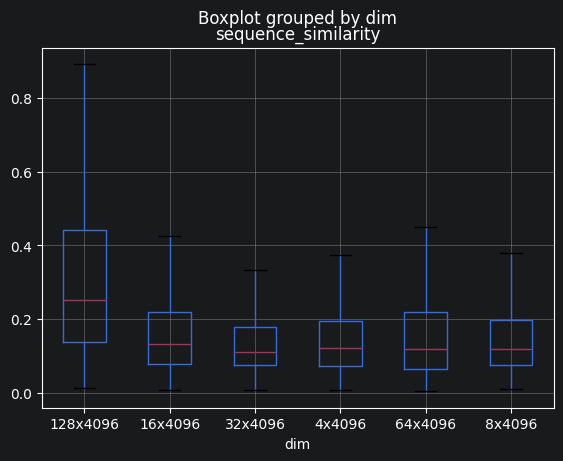

In [10]:
show_stats('sequence_similarity')

           count         mean          std  min      25%     50%      75%  \
dim                                                                         
128x4096  1546.0  1579.771669  1756.983594  0.0   423.00  1053.0  1968.00   
16x4096   1546.0  2308.748383  1534.838890  0.0  1608.25  2124.0  2624.75   
32x4096   1546.0  2320.107374  1608.996654  0.0  1469.25  1962.0  2667.50   
4x4096    1546.0  2377.793661  1607.496773  0.0  1494.75  2050.5  2763.50   
64x4096   1546.0  2506.123545  1653.355622  0.0  1736.50  2219.5  2962.75   
8x4096    1546.0  2289.690168  1537.866489  0.0  1398.75  2039.5  2604.00   

              max  median      IQR  
dim                                 
128x4096  16475.0  1053.0  1545.00  
16x4096   16291.0  2124.0  1016.50  
32x4096   16562.0  1962.0  1198.25  
4x4096    15843.0  2050.5  1268.75  
64x4096   16402.0  2219.5  1226.25  
8x4096    16483.0  2039.5  1205.25  


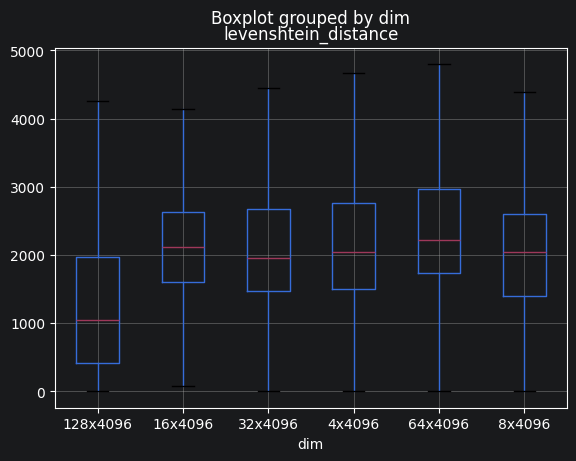

In [11]:
show_stats('levenshtein_distance')

           count      mean       std     min       25%      50%       75%  \
dim                                                                         
128x4096  1546.0  0.581820  0.195501  0.0531  0.465625  0.56320  0.680550   
16x4096   1546.0  0.387511  0.147533  0.0165  0.292375  0.38590  0.468100   
32x4096   1546.0  0.341002  0.153834  0.0455  0.224750  0.35270  0.434775   
4x4096    1546.0  0.370532  0.140879  0.0216  0.280425  0.37935  0.454025   
64x4096   1546.0  0.370314  0.158128  0.0552  0.267600  0.36605  0.456925   
8x4096    1546.0  0.395870  0.133093  0.0506  0.321100  0.39025  0.458800   

          max   median       IQR  
dim                               
128x4096  1.0  0.56320  0.214925  
16x4096   1.0  0.38590  0.175725  
32x4096   1.0  0.35270  0.210025  
4x4096    1.0  0.37935  0.173600  
64x4096   1.0  0.36605  0.189325  
8x4096    1.0  0.39025  0.137700  


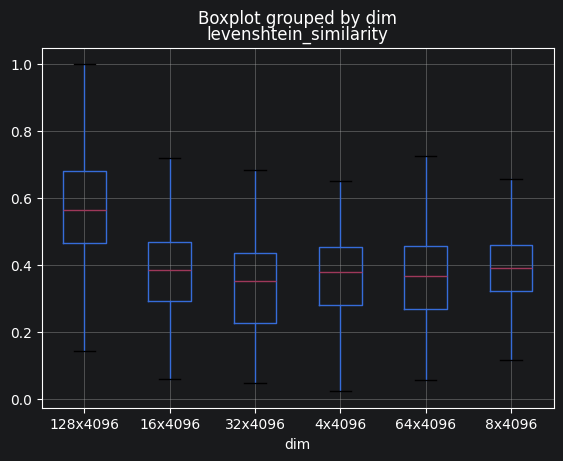

In [12]:
show_stats('levenshtein_similarity')

           count      mean       std  min  25%   50%      75%  max  median  \
dim                                                                          
128x4096  1546.0  0.346669  0.372822  0.0  0.0  0.25  0.62995  1.0    0.25   
16x4096   1546.0  0.056971  0.185053  0.0  0.0  0.00  0.00000  1.0    0.00   
32x4096   1546.0  0.035822  0.148477  0.0  0.0  0.00  0.00000  1.0    0.00   
4x4096    1546.0  0.067058  0.169909  0.0  0.0  0.00  0.00000  1.0    0.00   
64x4096   1546.0  0.052178  0.191044  0.0  0.0  0.00  0.00000  1.0    0.00   
8x4096    1546.0  0.041889  0.163847  0.0  0.0  0.00  0.00000  1.0    0.00   

              IQR  
dim                
128x4096  0.62995  
16x4096   0.00000  
32x4096   0.00000  
4x4096    0.00000  
64x4096   0.00000  
8x4096    0.00000  


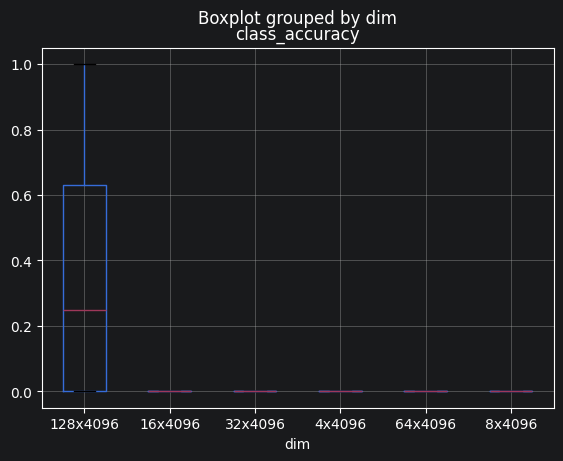

In [13]:
show_stats('class_accuracy')

           count      mean       std  min  25%     50%       75%  max  median  \
dim                                                                             
128x4096  1546.0  0.211493  0.317681  0.0  0.0  0.0541  0.265550  1.0  0.0541   
16x4096   1546.0  0.064050  0.194917  0.0  0.0  0.0000  0.003375  1.0  0.0000   
32x4096   1546.0  0.049840  0.159199  0.0  0.0  0.0000  0.002475  1.0  0.0000   
4x4096    1546.0  0.058782  0.165346  0.0  0.0  0.0000  0.042375  1.0  0.0000   
64x4096   1546.0  0.067895  0.217931  0.0  0.0  0.0000  0.000000  1.0  0.0000   
8x4096    1546.0  0.061732  0.194905  0.0  0.0  0.0000  0.011475  1.0  0.0000   

               IQR  
dim                 
128x4096  0.265550  
16x4096   0.003375  
32x4096   0.002475  
4x4096    0.042375  
64x4096   0.000000  
8x4096    0.011475  


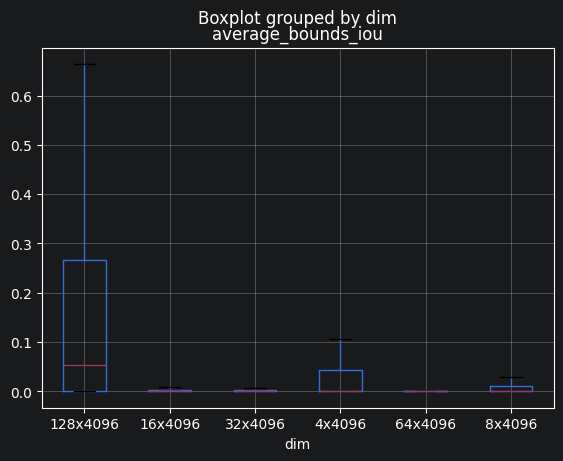

In [14]:
show_stats('average_bounds_iou')

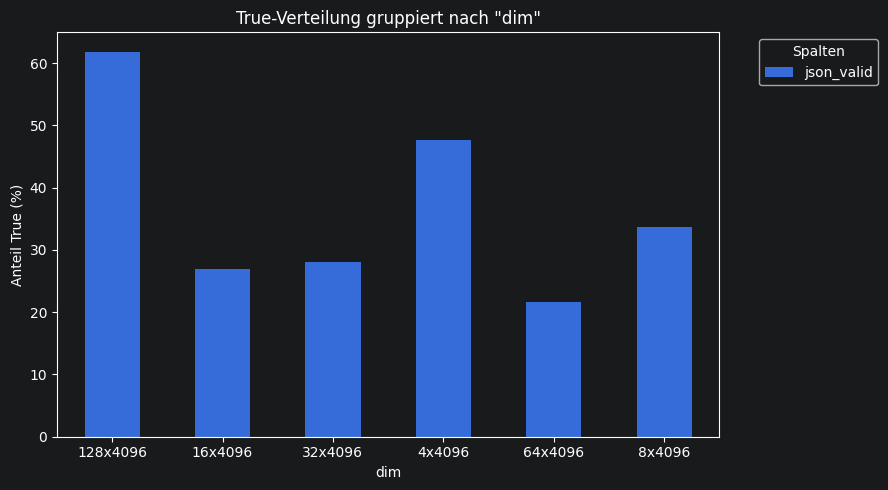

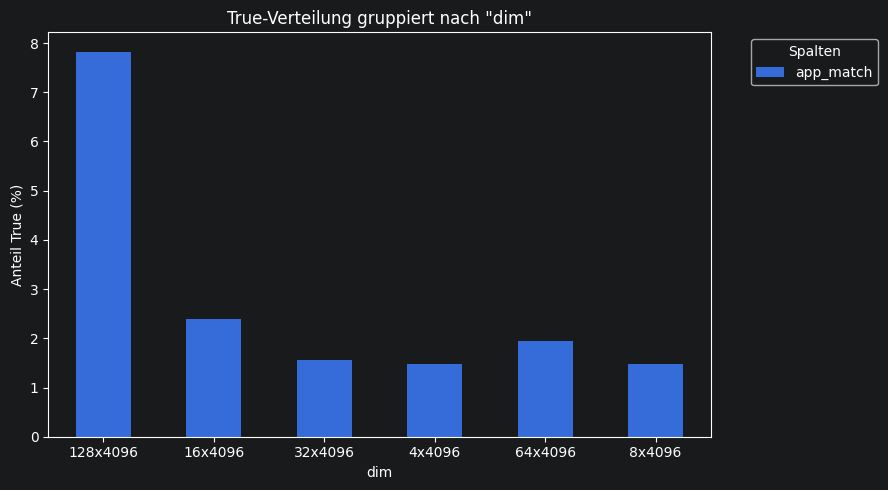

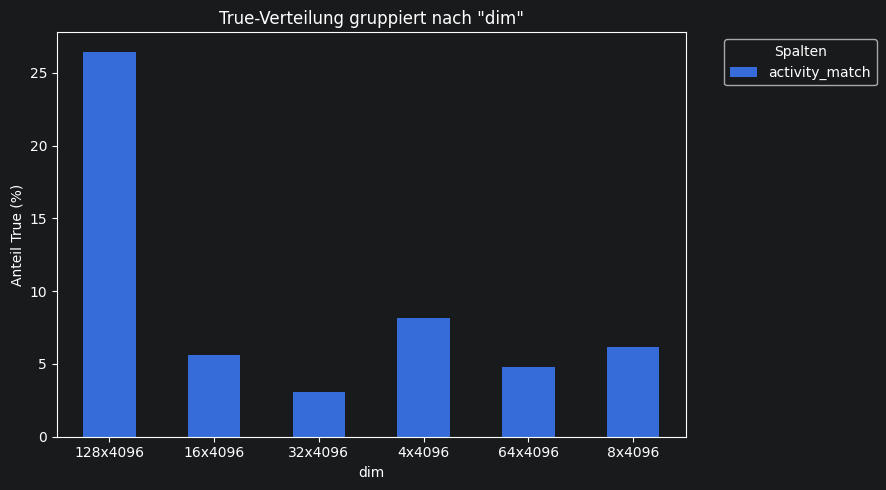

In [15]:
plot_bool_grouped(df, ['json_valid'], by="dim")
plot_bool_grouped(df, ['app_match'], by="dim")
plot_bool_grouped(df, ['activity_match'], by="dim")
